# Flowshopper : bootstrap AI, recommandeur par filtrage collaboratif
Notebook unique, exécutable de haut en bas (`Restart & Run All`). Les données MovieLens 100k sont lues dans `data/ml-100k/` (voir `README.md` pour les télécharger).

## 0. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity

# numpy 2.x + Accelerate (macOS) émet de faux RuntimeWarning dans matmul ; les résultats sont vérifiés plus bas.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

DATA = Path("data/ml-100k")
ratings = pd.read_csv(DATA / "u.data", sep="\t", header=None,
                      names=["user_id", "movie_id", "rating", "timestamp"])
movies = pd.read_csv(DATA / "u.item", sep="|", header=None, encoding="latin-1",
                     usecols=[0, 1], names=["movie_id", "title"])
print(ratings.shape, movies.shape)
ratings.head()

(100000, 4) (1682, 2)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## 1. La matrice des villageois

In [2]:
villagers = ["Tortimer", "Blathers", "K.K.", "Gulliver", "Resetti", "Isabelle"]
products = ["Baguette", "Cheese", "Apples", "Fish", "Honey", "Tea", "Pasta", "Chocolate"]
V = np.array([
    [5, 4, 0, 0, 5, 4, 0, 0],   # Tortimer
    [4, 5, 0, 1, 4, 5, 0, 5],   # Blathers
    [0, 1, 5, 4, 0, 0, 5, 2],   # K.K.
    [5, 0, 2, 0, 4, 0, 3, 0],   # Gulliver
    [1, 0, 4, 5, 0, 2, 5, 0],   # Resetti
    [0, 4, 0, 2, 5, 5, 0, 4],   # Isabelle
], dtype=float)
pd.DataFrame(V, index=villagers, columns=products).astype(int)

,Baguette,Cheese,Apples,Fish,Honey,Tea,Pasta,Chocolate
Tortimer,5,4,0,0,5,4,0,0
Blathers,4,5,0,1,4,5,0,5
K.K.,0,1,5,4,0,0,5,2
Gulliver,5,0,2,0,4,0,3,0
Resetti,1,0,4,5,0,2,5,0
Isabelle,0,4,0,2,5,5,0,4


### Cosinus à la main
Tortimer · Blathers = 5·4 + 4·5 + 5·4 + 4·5 = **80** ; ‖Tortimer‖ = √82 ; ‖Blathers‖ = √108 ; sim = 80 / √(82·108) ≈ **0,850**.

Tortimer · K.K. = 4·1 = **4** ; ‖K.K.‖ = √(1+25+16+25+4) = √71 ; sim = 4 / √(82·71) ≈ **0,052**.

Cohérent avec le tableau : Tortimer et Blathers notent presque pareil (baguette, fromage, miel, thé), alors que K.K. n'a presque rien en commun avec lui.

In [3]:
def cosine(u, v):
    """Similarité cosinus entre deux vecteurs (0 si l'un des deux est nul)."""
    nu, nv = np.linalg.norm(u), np.linalg.norm(v)
    if nu == 0 or nv == 0:
        return 0.0
    return float(u @ v / (nu * nv))

T, B, K = V[0], V[1], V[2]
print("Tortimer/Blathers", round(cosine(T, B), 3), "main:", round(80 / np.sqrt(82 * 108), 3))
print("Tortimer/K.K.    ", round(cosine(T, K), 3), "main:", round(4 / np.sqrt(82 * 71), 3))
assert np.isclose(cosine(T, B), 80 / np.sqrt(82 * 108))
assert np.isclose(cosine(T, K), 4 / np.sqrt(82 * 71))
assert np.isclose(cosine(T, T), 1.0) and cosine(T, np.zeros(8)) == 0.0

sims_T = np.array([cosine(V[0], V[j]) for j in range(len(V))])
for name, s in zip(villagers, sims_T):
    print(f"{name:9s} {s:.3f}")
nearest = 1 + np.argmax(sims_T[1:])
print("Plus proche voisin de Tortimer :", villagers[nearest])

Tortimer/Blathers 0.85 main: 0.85
Tortimer/K.K.     0.052 main: 0.052
Tortimer  1.000
Blathers  0.850
K.K.      0.052
Gulliver  0.676
Resetti   0.170
Isabelle  0.726
Plus proche voisin de Tortimer : Blathers


### Scores pour Tortimer
`score(u,i) = Σ_{v≠u} sim(u,v) × r_{v,i}`

In [4]:
w = sims_T.copy(); w[0] = 0.0          # on exclut Tortimer lui-même
scores = w @ V                          # un score par produit
unseen = V[0] == 0
table = pd.DataFrame({"score": scores.round(2), "déjà noté": ~unseen}, index=products)
print(table)
best = max((p for p, ok in zip(range(8), unseen) if ok), key=lambda i: scores[i])
print("Recommandation pour Tortimer :", products[best])

           score  déjà noté
Baguette    6.95       True
Cheese      7.21       True
Apples      2.30      False
Fish        3.36      False
Honey       9.74       True
Tea         8.22       True
Pasta       3.14      False
Chocolate   7.26      False
Recommandation pour Tortimer : Chocolate


**Le résultat a-t-il du sens ?** Les produits non notés par Tortimer sont Apples, Fish, Pasta et Chocolate. Chocolate arrive en tête : Blathers (très proche de lui, sim ≈ 0,85) l'a noté 5 et Isabelle (qui aime aussi baguette, fromage, miel, thé) l'a noté 4. Apples, Fish et Pasta sont portés par K.K. et Resetti, trop différents de Tortimer.

**Que signifie le 0 ?** Dans la similarité, un 0 ne contribue rien au produit scalaire : « jamais goûté le poisson » est traité comme une absence d'accord, ni accord ni désaccord. Ce n'est **pas** pareil que « déteste le poisson » (qui serait un 1). Remplir par 0 est une approximation : un utilisateur qui note tout 5 est plus « proche » de quelqu'un qui note beaucoup que de quelqu'un qui note peu, même si leurs goûts sont identiques. C'est la limite de ce bootstrap.

## 2. La matrice MovieLens

In [5]:
n_users, n_movies, n_ratings = ratings.user_id.nunique(), ratings.movie_id.nunique(), len(ratings)
print(f"{n_users} utilisateurs, {n_movies} films notés (catalogue : {len(movies)}), {n_ratings} notes")
print("Valeurs possibles :", sorted(int(x) for x in ratings.rating.unique()))
ratings.describe().loc[["min", "max", "mean"], ["rating"]]

943 utilisateurs, 1682 films notés (catalogue : 1682), 100000 notes
Valeurs possibles : [1, 2, 3, 4, 5]


,rating
min,1.00000
max,5.00000
mean,3.52986


In [6]:
UM = ratings.pivot_table(index="user_id", columns="movie_id", values="rating")
print("Forme :", UM.shape)
sparsity = UM.isna().to_numpy().mean()
print(f"Sparsité : {sparsity:.2%} de cases vides")
assert UM.shape == (n_users, n_movies)

# correspondances ligne <-> user_id, colonne <-> movie_id, colonne -> titre
user_ids = UM.index.to_numpy()
movie_ids = UM.columns.to_numpy()
row_of = {u: i for i, u in enumerate(user_ids)}
col_of = {m: j for j, m in enumerate(movie_ids)}
title_of_id = movies.set_index("movie_id").title
titles = np.array([str(title_of_id[m]) for m in movie_ids], dtype=object)    # titles[j] = titre de la colonne j

M = UM.fillna(0).to_numpy()
assert M.shape == UM.shape and (M > 0).sum() == n_ratings

Forme : (943, 1682)
Sparsité : 93.70% de cases vides


In [7]:
USER = 1                       # user_id choisi
u = row_of[USER]
print(f"Utilisateur {USER} : {(M[u] > 0).sum()} films notés. Films notés 5 :")
for t in titles[M[u] == 5][:15]:
    print(" -", t)

Utilisateur 1 : 272 films notés. Films notés 5 :
 - Toy Story (1995)
 - Shanghai Triad (Yao a yao yao dao waipo qiao) (1995)
 - Dead Man Walking (1995)
 - Usual Suspects, The (1995)
 - Mighty Aphrodite (1995)
 - Postino, Il (1994)
 - Mr. Holland's Opus (1995)
 - French Twist (Gazon maudit) (1995)
 - Antonia's Line (1995)
 - Crumb (1994)
 - Clerks (1994)
 - Dolores Claiborne (1994)
 - Eat Drink Man Woman (1994)
 - Hoop Dreams (1994)
 - Star Wars (1977)


## 3. Qui ressemble à qui ?

In [8]:
S = cosine_similarity(M)
print("Forme :", S.shape, "-> S[i, j] = similarité entre l'utilisateur de la ligne i et celui de la ligne j")
print("Diagonale :", np.unique(S.diagonal().round(6)), "(un vecteur est identique à lui-même : cosinus = 1)")
i, j = row_of[1], row_of[2]
assert np.isclose(S[i, j], cosine(M[i], M[j]))
print("Vérification avec ma fonction :", round(S[i, j], 4), "=", round(cosine(M[i], M[j]), 4))

Forme : (943, 943) -> S[i, j] = similarité entre l'utilisateur de la ligne i et celui de la ligne j
Diagonale : [1.] (un vecteur est identique à lui-même : cosinus = 1)
Vérification avec ma fonction : 0.1669 = 0.1669


In [9]:
def nearest_neighbors(user_row, n, sim=None):
    """Indices (lignes) des n plus proches voisins de user_row, avec leur similarité. Exclut l'utilisateur."""
    sim = S if sim is None else sim
    s = sim[user_row].copy()
    s[user_row] = -np.inf
    idx = np.argsort(s)[::-1][:n]
    return idx, s[idx]

idx, sims = nearest_neighbors(u, 5)
assert u not in idx
for r, s in zip(idx, sims):
    print(f"user {user_ids[r]:4d}  sim = {s:.3f}")
best = idx[0]
print(f"\nFilms notés 5 par le voisin le plus proche (user {user_ids[best]}), parmi ceux notés 5 par user {USER} aussi :")
common = set(titles[M[best] == 5]) & set(titles[M[u] == 5])
print(sorted(common)[:10] or "aucun")
print("Autres films 5 du voisin :", list(titles[M[best] == 5][:8]))

user  916  sim = 0.569
user  864  sim = 0.548
user  268  sim = 0.542
user   92  sim = 0.541
user  435  sim = 0.539

Films notés 5 par le voisin le plus proche (user 916), parmi ceux notés 5 par user 1 aussi :
['Big Night (1996)', 'Blade Runner (1982)', 'Chasing Amy (1997)', 'Clerks (1994)', 'Dead Man Walking (1995)', 'Empire Strikes Back, The (1980)', 'Fargo (1996)', 'Hoop Dreams (1994)', 'Hudsucker Proxy, The (1994)', 'Postino, Il (1994)']
Autres films 5 du voisin : ['Dead Man Walking (1995)', 'Postino, Il (1994)', 'Clerks (1994)', 'Hoop Dreams (1994)', 'Star Wars (1977)', 'Madness of King George, The (1994)', 'Pulp Fiction (1994)', 'Quiz Show (1994)']


Le voisin le plus proche partage plusieurs films notés 5 avec l'utilisateur 1 (les similarités sont élevées car les deux notent beaucoup de films populaires) : ils ont bien des goûts communs.

## 4. Recommander

In [10]:
def recommend(user_row, k=10, n_neighbors=20, M=None, S=None):
    """Top-k (colonne, score) des films non vus, d'après les n_neighbors plus proches voisins."""
    M = globals()["M"] if M is None else M
    S = globals()["S"] if S is None else S
    idx, sims = nearest_neighbors(user_row, n_neighbors, S)
    scores = sims @ M[idx]                    # (n,) @ (n, films) -> un score par film
    assert np.isfinite(scores).all()          # garde-fou contre les faux warnings matmul
    scores = np.where(M[user_row] > 0, -np.inf, scores)   # retire les films déjà notés
    top = np.argsort(scores)[::-1][:k]
    return [(int(c), float(scores[c])) for c in top]

def show(user_id, k=10, n_neighbors=20):
    r = row_of[user_id]
    rec = recommend(r, k, n_neighbors)
    assert all(M[r, c] == 0 for c, _ in rec), "recommandation d'un film déjà vu"
    for c, s in rec:
        print(f"  {s:7.2f}  {titles[c]}")

print(f"Films notés 5 par {USER} :", list(titles[M[u] == 5][:6]), "...")
print(f"\nTop 10 pour {USER} :")
show(USER)

Films notés 5 par 1 : ['Toy Story (1995)', 'Shanghai Triad (Yao a yao yao dao waipo qiao) (1995)', 'Dead Man Walking (1995)', 'Usual Suspects, The (1995)', 'Mighty Aphrodite (1995)', 'Postino, Il (1994)'] ...

Top 10 pour 1 :
    41.01  Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963)
    38.33  E.T. the Extra-Terrestrial (1982)
    37.41  Schindler's List (1993)
    37.13  One Flew Over the Cuckoo's Nest (1975)
    36.83  Stand by Me (1986)
    35.62  Batman (1989)
    34.77  Heathers (1989)
    34.41  Glory (1989)
    34.18  Speed (1994)
    32.60  Dave (1993)


In [11]:
# utilisateur aux goûts très différents : faible similarité, mais assez de notes pour être crédible
active = np.where((M > 0).sum(1) >= 100)[0]
other = active[np.argmin(S[u, active])]
print("Autre utilisateur :", user_ids[other], "sim avec", USER, "=", round(S[u, other], 3))
print("Ses films 5 :", list(titles[M[other] == 5][:6]))
print("Top 10 :"); show(int(user_ids[other]))
a = {c for c, _ in recommend(u)}; b = {c for c, _ in recommend(other)}
print("Films communs aux deux top 10 :", len(a & b))

Autre utilisateur : 489 sim avec 1 = 0.049
Ses films 5 : ['Contact (1997)', 'Kull the Conqueror (1997)', 'Good Will Hunting (1997)', 'Air Force One (1997)', 'L.A. Confidential (1997)', 'Apt Pupil (1998)']
Top 10 :
    27.79  Seven Years in Tibet (1997)
    18.69  Apostle, The (1997)
    17.01  Excess Baggage (1997)
    14.61  Ice Storm, The (1997)
    13.74  Mrs. Brown (Her Majesty, Mrs. Brown) (1997)
    13.45  Life Less Ordinary, A (1997)
    12.23  Thousand Acres, A (1997)
    11.16  Desperate Measures (1998)
    10.85  Fallen (1998)
    10.72  One Night Stand (1997)
Films communs aux deux top 10 : 0


**Ces recommandations sont-elles crédibles ?** Elles privilégient des films très populaires et bien notés, ce qui est cohérent mais peu surprenant. Les deux utilisateurs reçoivent des listes différentes, preuve que le système personnalise un minimum. Le garde-fou `assert` vérifie qu'aucun film déjà vu n'est jamais renvoyé.

### Expliquer

In [12]:
def explain(user_row, col, n_neighbors=20):
    idx, sims = nearest_neighbors(user_row, n_neighbors)
    rows = [(user_ids[r], s, int(M[r, col])) for r, s in zip(idx, sims) if M[r, col] > 0]
    rows.sort(key=lambda x: -x[1])
    best = rows[:3]
    who = ", ".join(f"l'utilisateur {uid} (similarité {s:.2f}) lui a mis {rt}/5" for uid, s, rt in best)
    avg = np.mean([rt for _, _, rt in rows])
    return (f"« {titles[col]} » vous est recommandé car {len(rows)} de vos {n_neighbors} voisins les plus proches "
            f"l'ont noté (moyenne {avg:.1f}/5), notamment {who}.")

first_col = recommend(u, 10, 20)[0][0]
print(explain(u, first_col))

« Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1963) » vous est recommandé car 18 de vos 20 voisins les plus proches l'ont noté (moyenne 4.3/5), notamment l'utilisateur 916 (similarité 0.57) lui a mis 4/5, l'utilisateur 864 (similarité 0.55) lui a mis 4/5, l'utilisateur 268 (similarité 0.54) lui a mis 5/5.


## 5. Est-ce que ça marche ?

In [13]:
def hide_and_rank(user_row, col, n_neighbors=20, k=10):
    """Masque la note (user, col), recalcule la similarité APRÈS le masquage, renvoie le rang du film caché."""
    M2 = M.copy()
    M2[user_row, col] = 0
    S2 = cosine_similarity(M2)               # recalculé sur la matrice masquée : pas de fuite
    idx, sims = nearest_neighbors(user_row, n_neighbors, S2)
    scores = sims @ M2[idx]
    assert np.isfinite(scores).all()
    scores = np.where(M2[user_row] > 0, -np.inf, scores)
    # rang = 1 + nombre de films strictement mieux classés ; un score 0 ne compte pas comme trouvé
    rank = 1 + int((scores > scores[col]).sum())
    return rank if scores[col] > 0 else None

rank = hide_and_rank(u, np.where(M[u] == 5)[0][0])
print("Rang du film caché pour l'utilisateur", USER, ":", rank)

Rang du film caché pour l'utilisateur 1 : 1


In [14]:
rng = np.random.default_rng(42)
test_rows = rng.choice(np.where((M == 5).sum(1) > 0)[0], size=50, replace=False)
picks = {r: int(rng.choice(np.where(M[r] == 5)[0])) for r in test_rows}   # mêmes films masqués pour tous les réglages

def run_test(n_neighbors=20):
    ranks = [hide_and_rank(r, c, n_neighbors) for r, c in picks.items()]
    return ranks

ranks = run_test(20)
found10 = sum(r is not None and r <= 10 for r in ranks)
found50 = sum(r is not None and r <= 50 for r in ranks)
print(f"n_neighbors=20 : top 10 -> {found10}/50 utilisateurs ; top 50 -> {found50}/50")

n_neighbors=20 : top 10 -> 22/50 utilisateurs ; top 50 -> 34/50


             top10  top50  non trouvé  rang médian
n_neighbors                                       
5               23     31           5          9.0
20              22     34           0         15.0
50              21     35           0         18.0
200             21     35           0         19.0


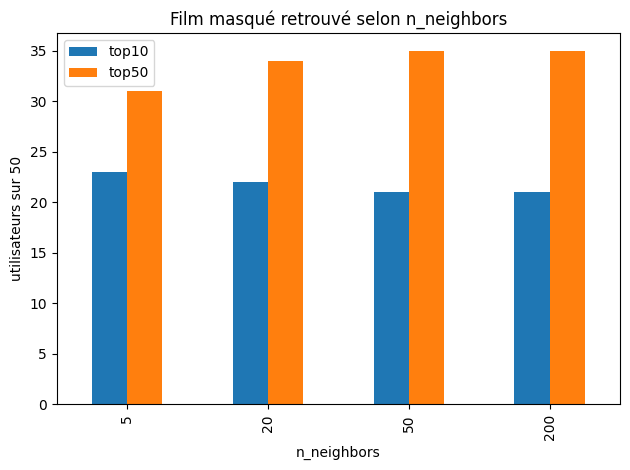

In [15]:
results = []
for n in [5, 20, 50, 200]:
    rk = run_test(n)
    results.append({"n_neighbors": n,
                    "top10": sum(r is not None and r <= 10 for r in rk),
                    "top50": sum(r is not None and r <= 50 for r in rk),
                    "non trouvé": sum(r is None for r in rk),
                    "rang médian": float(np.median([r for r in rk if r is not None])) if any(r for r in rk) else None})
res = pd.DataFrame(results).set_index("n_neighbors")
print(res)
res[["top10", "top50"]].plot(kind="bar", ylabel="utilisateurs sur 50", title="Film masqué retrouvé selon n_neighbors")
plt.tight_layout(); plt.show()

**Quelle valeur garder ?** Les résultats sont presque plats : top 10 entre 21 et 23 sur 50, top 50 entre 31 et 35. Avec 5 voisins le top 10 est légèrement meilleur, mais 5 utilisateurs n'ont aucune recommandation exploitable (aucun voisin n'a vu le film). Au-delà de 50 voisins le top 50 ne progresse plus. On garde **n_neighbors = 20** : zéro film introuvable, top 50 proche du maximum, et des explications lisibles (20 voisins). Avec 50 utilisateurs la marge d'erreur est de l'ordre de ±7 points : ces écarts ne sont pas significatifs.

**Précision et rappel pour une liste de k films.** Pour une liste de k films recommandés et un ensemble de films pertinents cachés :
- *précision@k* = (pertinents dans la liste) / k : quelle part de la liste est utile ;
- *rappel@k* = (pertinents dans la liste) / (nombre de pertinents) : quelle part des films aimés on retrouve.

Avec un seul film caché, rappel@k vaut 1 ou 0 (c'est le « taux de réussite » mesuré ci-dessus) et précision@k vaut au mieux 1/k. On le teste avec plusieurs films cachés par utilisateur.

In [16]:
def precision_recall_at_k(user_row, k=10, n_hidden=5, n_neighbors=20, seed=0):
    r = np.random.default_rng(seed + user_row)
    fives = np.where(M[user_row] == 5)[0]
    if len(fives) <= n_hidden:
        return None
    hidden = r.choice(fives, size=n_hidden, replace=False)
    M2 = M.copy(); M2[user_row, hidden] = 0
    S2 = cosine_similarity(M2)
    rec = [c for c, s in recommend(user_row, k, n_neighbors, M2, S2) if s > 0]
    hits = len(set(rec) & set(hidden))
    return hits / k, hits / n_hidden

pr = [x for x in (precision_recall_at_k(r) for r in test_rows) if x]
print(f"{len(pr)} utilisateurs : précision@10 = {np.mean([p for p, _ in pr]):.3f}, rappel@10 = {np.mean([q for _, q in pr]):.3f}")

41 utilisateurs : précision@10 = 0.166, rappel@10 = 0.332


## 6. Au-delà des notes
- **Rien ne dit qu'un villageois n'aime pas un produit** : un achat est un feedback implicite positif, l'absence d'achat est ambiguë. Un signal négatif doit venir d'ailleurs (retour, remplacement par un autre produit, suppression du panier, avis).
- **Une case vide** peut signifier « n'aime pas », « ne connaît pas » ou « l'achète ailleurs » : impossible de trancher. Il faut donc traiter vide = inconnu, pas vide = 0 négatif (pondération, échantillonnage de négatifs, ALS implicite).
- **Achats récurrents** : on met le nombre d'achats (ou son log, ou une version normalisée par l'utilisateur) plutôt que 1/0, car acheter du lait 40 fois dit plus qu'un achat unique.
- **Ne pas recommander ce qui est déjà acheté ?** Non : en épicerie, le réachat est la norme. Il faut recommander les produits récurrents au bon moment, et mettre les nouveautés à part.
- **Comparer les produits plutôt que les utilisateurs** (filtrage item-item) : on recommande des produits proches de ceux déjà achetés. C'est plus stable (un catalogue change moins vite qu'une base d'utilisateurs), plus facile à expliquer (« parce que vous achetez X »), et ça aide au démarrage à froid d'un nouvel utilisateur.

> La meilleure recommandation est celle dont le villageois ne savait pas qu'il avait besoin.